<a href="https://colab.research.google.com/github/wararit-panichkitkosolkul/bike-sharing-DS512/blob/main/Bike_Sharing_Homework_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **DS514/515: Data Science**

## **ตัวแบบการเรียนรู้ของเครื่องเบื้องต้นเพื่อทำนายจำนวนครั้งการเช่าจักรยานสาธารณะรายวัน**
การศึกษาตัวแบบการเรียนรู้ของเครื่อง (Machine Learning) เบื้องต้น ในการพยากรณ์จำนวนครั้งการเช่าจักรยานสาธารณะรายวัน โดยวิเคราะห์ร่วมกับตัวแปรสภาพอากาศและแนวโน้มเชิงเวลา

# สมาชิกในกลุ่ม
1. นายก้องภพ สายสุด (รหัสนิสิต 69199160398)
2. นายพศวีร์ คอนจอหอ  (รหัสนิสิต 69199160411)
3. นายวราฤทธิ์ พานิชกิจโกศลกุล  (รหัสนิสิต 69199160420)

# L0 - Data Preparation and Data Claning

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import pandas as pd

#การอ่านแฟ้มข้อมูล
bike = pd.read_csv('/content/drive/MyDrive/Bike_Sharing_Data.csv')

Data Dictionary
| ตัวแปร | ความหมาย | ชนิดข้อมูล | รหัส / หน่วย / รายละเอียด |
|---|---|---|---|
| `instant` | ลำดับระเบียนข้อมูล | จำนวนเต็ม — ตัวระบุ | ใช้ระบุแถวข้อมูล |
| `dteday` | วันที่บันทึกข้อมูล | วันที่ | รูปแบบ `YYYY-MM-DD` |
| `season` | ฤดูกาล | หมวดหมู่ | 1 = ฤดูหนาว, 2 = ฤดูใบไม้ผลิ, 3 = ฤดูร้อน, 4 = ฤดูใบไม้ร่วง |
| `yr` | ปีที่บันทึกข้อมูล | หมวดหมู่ | 0 = ค.ศ. 2011, 1 = ค.ศ. 2012 |
| `mnth` | เดือน | หมวดหมู่ | 1 = มกราคม ถึง 12 = ธันวาคม |
| `holiday` | สถานะวันหยุด | ทวิภาค | 0 = ไม่ใช่วันหยุด, 1 = วันหยุด |
| `weekday` | วันในสัปดาห์ | หมวดหมู่ | รหัส 0–6; ตรวจสอบชื่อวันเทียบกับ `dteday` |
| `workingday` | สถานะวันทำงาน | ทวิภาค | 1 = วันทำงาน, 0 = วันเสาร์–อาทิตย์หรือวันหยุด |
| `weathersit` | ประเภทสภาพอากาศ | หมวดหมู่ | 1 = แจ่มใสหรือมีเมฆบางส่วน; 2 = มีหมอกบางหรือหมอกร่วมกับเมฆ; 3 = ฝนหรือหิมะเล็กน้อย อาจมีพายุฝนฟ้าคะนอง; 4 = ฝนหนักร่วมกับพายุหรือเม็ดน้ำแข็ง หรือหิมะร่วมกับหมอก |
| `temp` | อุณหภูมิที่ปรับสเกลแล้ว | ตัวเลขทศนิยม | ค่า normalized; ตรวจสอบสูตรก่อนแปลงกลับเป็น °C |
| `atemp` | อุณหภูมิที่ร่างกายรู้สึก ซึ่งปรับมาตราส่วนแล้ว | ตัวเลขทศนิยม | ค่า normalized; ตรวจสอบสูตรก่อนแปลงกลับเป็น °C |
| `hum` | ความชื้นสัมพัทธ์ที่ปรับสเกลแล้ว | ตัวเลขทศนิยม | ความชื้นสัมพัทธ์ (%) ÷ 100 |
| `windspeed` | ความเร็วลมที่ปรับมาตราส่วนแล้ว | ตัวเลขทศนิยม | ความเร็วลมเดิม ÷ 67 |
| `casual` | จำนวนครั้งการเช่าของผู้ใช้ทั่วไป | จำนวนเต็ม | ครั้งต่อวัน |
| `registered` | จำนวนครั้งการเช่าของสมาชิก | จำนวนเต็ม | ครั้งต่อวัน |
| `cnt` | จำนวนครั้งการเช่า (ตัวแปรเป้าหมาย) | จำนวนเต็ม | ครั้งต่อวัน; `cnt = casual + registered` |

การวิเคราะห์ข้อมูลเชิงสำรวจ (EDA) เบื้องต้น

In [7]:
# ดูข้อมูลเบื้องต้น
print(bike.head())

# ตรวจสอบขนาดข้อมูล
print(bike.shape)

# ตรวจสอบชนิดข้อมูล
print(bike.info())

   instant    dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  1/1/2011       1   0     1        0        6           0   
1        2  2/1/2011       1   0     1        0        0           0   
2        3  3/1/2011       1   0     1        0        1           1   
3        4  4/1/2011       1   0     1        0        2           1   
4        5  5/1/2011       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  
(731, 16)
<class 'pandas.core.frame.Da

In [8]:
#เปลี่ยนชนิดของตัวแปร yr จาก int ให้เป็น category
bike['yr'] = bike['yr'].astype('category')

#แปลงข้อความให้เป็นข้อมูลประเภทวันที่
bike['dteday'] = pd.to_datetime(bike['dteday'], dayfirst=True)

#ดึงปีจากวันที่ แล้วสร้างเป็นคอลัมน์ใหม่ชื่อ year
bike['year'] = bike['dteday'].dt.year

#เปลี่ยนชนิดของตัวแปร year จาก int ให้เป็น category
bike['year'] = bike['year'].astype('category')

#เปลี่ยนชนิดของตัวแปร season จาก int ให้เป็น category
bike['season'] = bike['season'].astype('category')

#เปลี่ยนชนิดของตัวแปร mnth จาก int ให้เป็น category
bike['mnth'] = bike['mnth'].astype('category')

#เปลี่ยนชนิดของตัวแปร holiday จาก int ให้เป็น bool
bike['holiday'] = bike['holiday'].astype('bool')

#เปลี่ยนชนิดของตัวแปร weekday จาก int ให้เป็น category
bike['weekday'] = bike['weekday'].astype('category')

#เปลี่ยนชนิดของตัวแปร working จาก int ให้เป็น bool
bike['workingday'] = bike['workingday'].astype('bool')

#เปลี่ยนชนิดของตัวแปร weathersit จาก int ให้เป็น category
bike['weathersit'] = bike['weathersit'].astype('category')

In [9]:
#ตรวจสอบว่า แต่ละตัวแปรมีค่า null หรือไม่
print(bike.isnull().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
year          0
dtype: int64


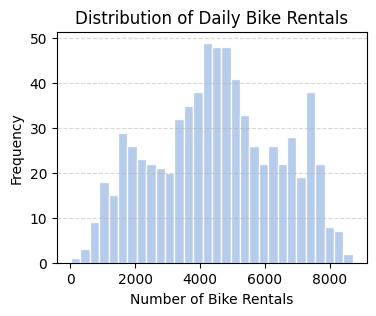

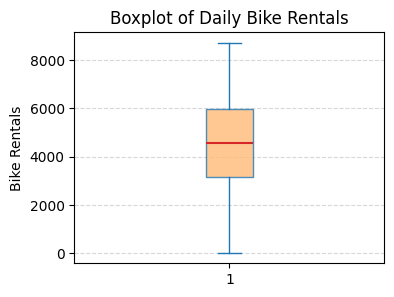

In [11]:
import matplotlib.pyplot as plt

#Histogram ของจำนวนการเช่าจักรยาน
plt.figure(figsize = [4,3])
plt.hist(bike['cnt'], bins=30, color='#aec7e8', edgecolor='white', alpha=0.9)
plt.xlabel('Number of Bike Rentals')
plt.ylabel('Frequency')
plt.title('Distribution of Daily Bike Rentals')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

#Boxplot ของจำนวนการเช่าจักรยาน
plt.figure(figsize = [4,3])
plt.boxplot(bike['cnt'], patch_artist=True,
            boxprops=dict(facecolor='#ffbb78', color='#1f77b4', alpha=0.8),
            capprops=dict(color='#1f77b4'),
            whiskerprops=dict(color='#1f77b4'),
            flierprops=dict(marker='o', markerfacecolor='#ff9896', markersize=6, linestyle='none'),
            medianprops=dict(color='#d62728', linewidth=1.5))
plt.ylabel('Bike Rentals')
plt.title('Boxplot of Daily Bike Rentals')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [12]:
# ดูภาพรวมของตัวแปรเชิงปริมาณ
bike.describe()

,instant,dteday,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


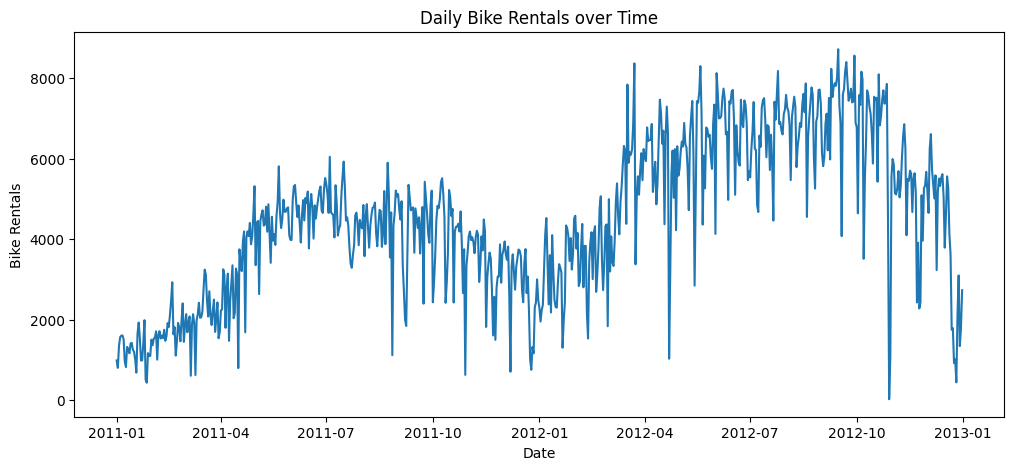

In [13]:
#พิจารณาแนวโน้มของจำนวนครั้งการเช่าจักรยานตามลำดับเวลา
plt.figure(figsize=(12, 5))
plt.plot(bike['dteday'], bike['cnt'])
plt.xlabel('Date')
plt.ylabel('Bike Rentals')
plt.title('Daily Bike Rentals over Time')
plt.show()

Correlation Analysis

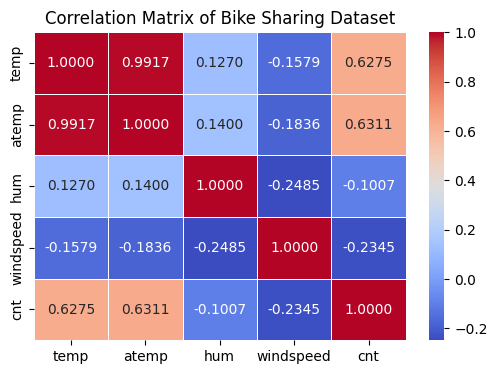

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_vec = ['temp', 'atemp', 'hum', 'windspeed',  'cnt']

correlation_matrix = bike[numeric_vec].corr()

# Plot the heatmap of the correlation matrix with 4 decimal places
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, fmt='.4f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Bike Sharing Dataset')
plt.show()

ผลการวิเคราะห์ค่าสัมประสิทธิ์สหสัมพันธ์ของเพียร์สันพบว่า อุณหภูมิ (temp) และอุณหภูมิที่ผู้ใช้รับรู้ (atemp) มีความสัมพันธ์เชิงบวกกับจำนวนการเช่าจักรยาน (cnt) ในระดับปานกลางถึงค่อนข้างสูง โดยมีค่าสัมประสิทธิ์สหสัมพันธ์เท่ากับ 0.6275 และ 0.6311 ตามลำดับ ขณะที่ความชื้น (hum) และความเร็วลม (windspeed มีความสัมพันธ์เชิงลบกับจำนวนการเช่า โดยมีค่าสัมประสิทธิ์เท่ากับ -0.1007 และ -0.2345 ตามลำดับ

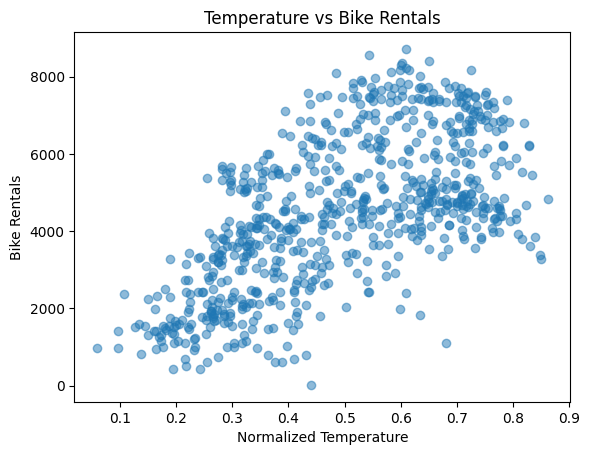

In [16]:
#Scatter Plot ระหว่างอุณหภูมิกับจำนวนการเช่า
plt.scatter(bike['temp'], bike['cnt'], alpha=0.5)

plt.xlabel('Normalized Temperature')
plt.ylabel('Bike Rentals')
plt.title('Temperature vs Bike Rentals')
plt.show()

Data Preprocessing

In [18]:
# การกำหนดคอลัมน์ตัวแปรเชิงกลุ่มและตัวแปรต่อเนื่อง
categorical_columns = ['season','yr','mnth','holiday','weekday','workingday','weathersit']
continuous_columns = ['temp','hum','windspeed']

In [20]:
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# การปรับสเกลตัวแปรต่อเนื่องด้วย MinMaxScaler
scaler = MinMaxScaler()
encoder = OneHotEncoder(sparse_output=False)

In [21]:
# การเข้ารหัส (Encoding) ตัวแปรเชิงกลุ่มด้วย OneHotEncoder
x_scaled = scaler.fit_transform(bike[continuous_columns])
x_encoded = encoder.fit_transform(bike[categorical_columns])

In [22]:
# การรวมข้อมูลตัวแปรต่อเนื่องที่ปรับสเกลแล้วกับข้อมูลตัวแปรเชิงกลุ่มที่เข้ารหัสแล้ว
x_combined = pd.concat([pd.DataFrame(x_scaled),pd.DataFrame(x_encoded)],axis=1)
y = bike['cnt']

# L9.1 - Linear Regression Model

In [23]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = bike[continuous_columns + categorical_columns]
y = bike["cnt"]

# ใช้ค่าตัวแปรเชิงปริมาณตามไฟล์ และเข้ารหัสเฉพาะตัวแปรเชิงกลุ่ม
preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", "passthrough", continuous_columns),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_columns,
        ),
    ]
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression()),
    ]
)

# L9.1 ใช้ข้อมูลทั้งหมด fit model
linear_model.fit(X, y)
y_pred = linear_model.predict(X)

rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f"จำนวนแถว: {X.shape[0]}")
print(f"RMSE: {rmse:.6f} ครั้งต่อวัน")
print(f"R2: {r2:.6f}")

จำนวนแถว: 731
RMSE: 754.634362 ครั้งต่อวัน
R2: 0.848045


=== คำอธิบายผลลัพธ์ของ Linear Regression Model (L9.1) ===

1. **ประสิทธิภาพและการทำนายของตัวแบบ (Model Performance):**
   - **ค่า RMSE (Root Mean Squared Error) เท่ากับ 754.634362 ครั้งต่อวัน** แสดงให้เห็นว่าโดยเฉลี่ยแล้ว ค่าที่ตัวแบบทำนายจะคลาดเคลื่อนไปจากจำนวนการเช่าจักรยานจริงประมาณ 755 ครั้งต่อวัน
   - **ค่า R-squared (R²) เท่ากับ 0.848045** บ่งชี้ว่าตัวแปรอิสระทั้งหมดในแบบจำลอง (ทั้งตัวแปรสภาพอากาศที่ปรับสเกลแล้ว และตัวแปรเชิงกลุ่มที่เข้ารหัสแล้ว) สามารถร่วมกันอธิบายความผันแปรของจำนวนครั้งการเช่าจักรยานรายวัน (`cnt`) ได้สูงถึง **84.80%** ซึ่งจัดว่าเป็นตัวแบบที่มีประสิทธิภาพในการทำนายดีมากสำหรับข้อมูลเชิงกายภาพและสภาพแวดล้อมนี้

2. **ข้อสังเกตเพิ่มเติม:**
   - เมื่อเปรียบเทียบกับแบบจำลอง Baseline (ที่ทำนายด้วยค่าเฉลี่ยอย่างเดียวซึ่งมีค่า RMSE สูงถึงประมาณ 1935.88 ครั้งต่อวัน) โมเดล Linear Regression ตัวนี้สามารถลดความคลาดเคลื่อนลงได้อย่างมีนัยสำคัญและแสดงโครงสร้างความสัมพันธ์เชิงเส้นที่ดีระหว่างปัจจัยแวดล้อมต่างๆ กับการตัดสินใจเช่าใช้งานจักรยานในแต่ละวัน

#L9.2 - Regularized Regression Model (Ridge Regression Model)

In [24]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline


def evaluate_regression(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# 1. คะแนนจาก Linear Regression ที่ fit แล้วใน L9.1
linear_scores = evaluate_regression(y, linear_model.predict(X))

# 2. Baseline ที่ทำนายค่าเฉลี่ยของ cnt ให้ทุกแถว
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X, y)
baseline_scores = evaluate_regression(y, baseline_model.predict(X))

# 3. ทดลอง Ridge ด้วย alpha บนกริดลอการิทึม
alphas = np.logspace(-4, 4, num=9)
results = []

for alpha in alphas:
    ridge_model = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("regression", Ridge(alpha=alpha)),
        ]
    )
    ridge_model.fit(X, y)
    scores = evaluate_regression(y, ridge_model.predict(X))
    results.append({"alpha": alpha, **scores})

ridge_results = pd.DataFrame(results)
best_result = ridge_results.loc[ridge_results["RMSE"].idxmin()]
best_alpha = best_result["alpha"]

print("ผลลัพธ์ Ridge Regression สำหรับ alpha แต่ละค่า")
display(ridge_results.style.format({"alpha": "{:.4g}", "RMSE": "{:.6f}", "R2": "{:.6f}"}))

# 4. เปรียบเทียบทั้งสามวิธีด้วยข้อมูลชุดเดียวกัน
comparison = pd.DataFrame([
    {"Model": "Baseline (mean)", **baseline_scores},
    {"Model": "Linear Regression", **linear_scores},
    {
        "Model": f"Ridge Regression (alpha={best_alpha:g})",
        "RMSE": best_result["RMSE"],
        "R2": best_result["R2"],
    },
])

print("เปรียบเทียบ Score บนข้อมูลทั้งหมด")
display(comparison.style.format({"RMSE": "{:.6f}", "R2": "{:.6f}"}))

# 5. ค่าที่ใช้กรอกใน L9.2 เมื่อ RMSE เป็น metric หลัก
print("tuned_param = alpha")
print("values_tried =", ", ".join(f"{alpha:g}" for alpha in alphas))
print(f"best_value   = {best_alpha:g}")
print(f"score_before = {linear_scores['RMSE']:.6f}")
print(f"score_after  = {best_result['RMSE']:.6f}")
print(f"baseline     = {baseline_scores['RMSE']:.6f}")

ผลลัพธ์ Ridge Regression สำหรับ alpha แต่ละค่า


,alpha,RMSE,R2
0,0.0001,754.634362,0.848045
1,0.001,754.634370,0.848045
2,0.01,754.635159,0.848045
3,0.1,754.708960,0.848015
4,1,758.963719,0.846297
5,10,805.533771,0.826856
6,100,1004.899608,0.730545
7,1000,1605.347257,0.312333
8,1e+04,1892.263263,0.044560


เปรียบเทียบ Score บนข้อมูลทั้งหมด


,Model,RMSE,R2
0,Baseline (mean),1935.885956,0.000000
1,Linear Regression,754.634362,0.848045
2,Ridge Regression (alpha=0.0001),754.634362,0.848045


tuned_param = alpha
values_tried = 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000
best_value   = 0.0001
score_before = 754.634362
score_after  = 754.634362
baseline     = 1935.885956


=== คำอธิบายผลลัพธ์ Ridge Regression Model (L9.2) ===

1. **ผลกระทบของค่า Alpha (Regularization Strength):**
   - เมื่อค่า `alpha` เพิ่มขึ้น (จาก `0.0001` ไปจนถึง `10,000`) ค่าความคลาดเคลื่อน **RMSE จะค่อยๆ เพิ่มสูงขึ้น** (จาก `754.634362` ไปเป็น `1892.263263` ครั้งต่อวัน) ขณะที่ค่า **R-squared ($R^2$) จะค่อยๆ ลดลง**อย่างต่อเนื่อง (จาก `0.848045` ลดลงเหลือเพียง `0.044560`)
   - แสดงว่าระดับความต้องการลดความซับซ้อน (Regularization) ที่สูงจนเกินไป ทำให้โมเดลเกิดภาวะ Underfitting (เรียนรู้ได้ไม่ดีเท่าที่ควร)

2. **การคัดเลือกตัวแปรพารามิเตอร์ที่ดีที่สุด:**
   - ค่าพารามิเตอร์ที่ดีที่สุดจากการทดลองบนชุดข้อมูลนี้คือ **`alpha = 0.0001`** ซึ่งให้ผลลัพธ์ใกล้เคียงกับการไม่ทำ Regularization เลย
   - โดยให้ค่า **RMSE ต่ำที่สุดที่ 754.634362 ครั้งต่อวัน** และค่า **$R^2$ สูงสุดที่ 0.848045** (สามารถอธิบายความผันแปรของปริมาณการเช่าจักรยานรายวันได้ถึง **84.80%**)

3. **การเปรียบเทียบประสิทธิภาพภาพรวม (Model Comparison):**
   - **Baseline (ทำนายด้วยค่าเฉลี่ย):** มีความคลาดเคลื่อนสูงมากด้วยค่า RMSE เท่ากับ `1935.885956` และ $R^2 = 0.000000$
   - **Linear Regression (L9.1):** มีค่า RMSE เท่ากับ `754.634362` และ $R^2 = 0.848045$
   - **Ridge Regression (alpha=0.0001):** มีค่า RMSE เท่ากับ `754.634362` และ $R^2 = 0.848045$
   - **บทสรุป:** การปรับใช้ Ridge Regression ด้วยค่า `alpha` ที่น้อยมาก ช่วยคงประสิทธิภาพการทำนายที่ยอดเยี่ยมไว้ได้ดีเท่ากับโมเดลถดถอยเชิงเส้นธรรมดา และสามารถลดความผิดพลาดจาก Baseline เดิมลงได้อย่างมีนัยสำคัญ

# L10 - Decision Tree Regression Model

ผลการทดลอง max_depth


,max_depth,RMSE,R2
0,2,1090.576955,0.682639
1,3,886.095363,0.790492
2,4,773.469209,0.840366
3,5,685.681534,0.874546
4,8,437.009323,0.949041
5,10,319.046747,0.972839
6,15,109.346835,0.996810


ผลการทดลอง min_samples_leaf


,min_samples_leaf,RMSE,R2
0,1,685.681534,0.874546
1,2,694.643500,0.871245
2,5,715.239422,0.863497
3,10,745.638285,0.851647
4,15,769.221379,0.842114
5,20,794.427327,0.831597


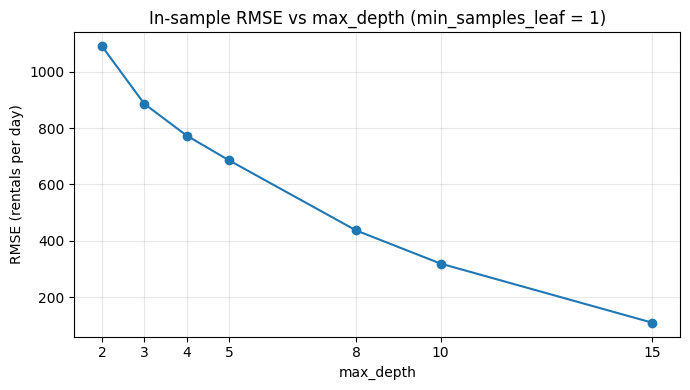

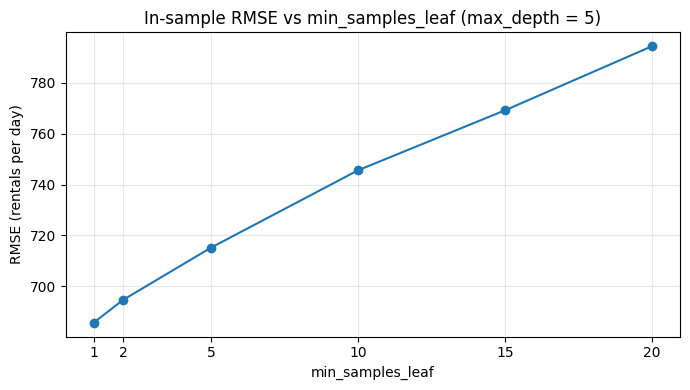


โหนดของต้นไม้ตัดสินใจตัวอย่าง (max_depth=5, min_samples_leaf=1)
Top node (root): continuous__temp <= 0.432373
Second-level node (left): categorical__yr_0 <= 0.5
Second-level node (right): categorical__yr_1 <= 0.5


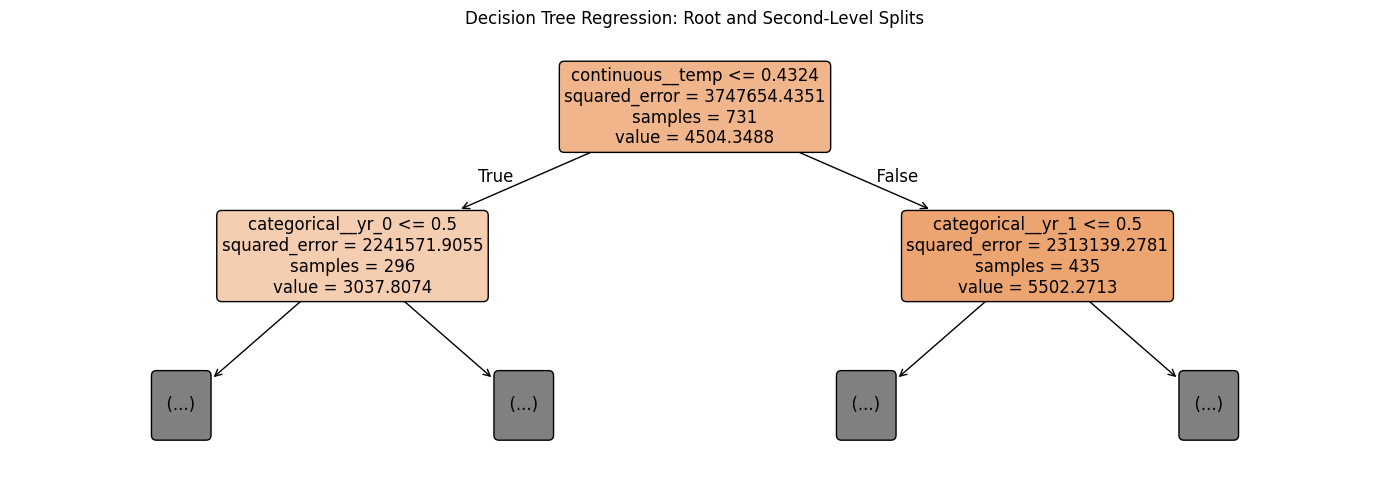

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree

# 1. เตรียมข้อมูลทั้งหมดด้วย preprocessing เดียวกับ L9.1
tree_preprocessor = clone(preprocessor)
X_tree = tree_preprocessor.fit_transform(X)
feature_names = tree_preprocessor.get_feature_names_out()


def fit_tree(max_depth=None, min_samples_leaf=1):
    model = DecisionTreeRegressor(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=42,
    )
    model.fit(X_tree, y)
    return model


def tree_scores(model):
    predictions = model.predict(X_tree)
    return {
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions),
    }


# 2. ทดลอง max_depth โดยกำหนด min_samples_leaf = 1
depth_values = [2, 3, 4, 5, 8, 10, 15]
depth_results = pd.DataFrame([
    {"max_depth": depth, **tree_scores(fit_tree(max_depth=depth))}
    for depth in depth_values
])

# 3. ทดลอง min_samples_leaf โดยกำหนด max_depth = 5
leaf_values = [1, 2, 5, 10, 15, 20]
leaf_results = pd.DataFrame([
    {
        "min_samples_leaf": leaf_size,
        **tree_scores(fit_tree(max_depth=5, min_samples_leaf=leaf_size)),
    }
    for leaf_size in leaf_values
])

print("ผลการทดลอง max_depth")
display(depth_results.style.format({"RMSE": "{:.6f}", "R2": "{:.6f}"}))

print("ผลการทดลอง min_samples_leaf")
display(leaf_results.style.format({"RMSE": "{:.6f}", "R2": "{:.6f}"}))

# 4. สร้างกราฟ 2 รูปและบันทึก
for results, parameter, fixed_setting, filename in [
    (depth_results, "max_depth", "min_samples_leaf = 1", "L10_RMSE_vs_max_depth.png"),
    (leaf_results, "min_samples_leaf", "max_depth = 5", "L10_RMSE_vs_min_samples_leaf.png"),
]:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(results[parameter], results["RMSE"], marker="o")
    ax.set(
        title=f"In-sample RMSE vs {parameter} ({fixed_setting})",
        xlabel=parameter,
        ylabel="RMSE (rentals per day)",
        xticks=results[parameter],
    )
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

# 5. ใช้ต้นไม้ตัวอย่าง depth = 5 เพื่อรายงานโหนด 2 ระดับแรก
example_tree = fit_tree(max_depth=5, min_samples_leaf=1)
structure = example_tree.tree_


def describe_node(label, node_id):
    if structure.children_left[node_id] == -1:
        prediction = structure.value[node_id, 0, 0]
        print(f"{label}: leaf node, predicted cnt = {prediction:.2f}")
        return

    feature = feature_names[structure.feature[node_id]]
    threshold = structure.threshold[node_id]
    print(f"{label}: {feature} <= {threshold:.6g}")


print("\nโหนดของต้นไม้ตัดสินใจตัวอย่าง (max_depth=5, min_samples_leaf=1)")
describe_node("Top node (root)", 0)
if structure.children_left[0] != -1:
    describe_node("Second-level node (left)", structure.children_left[0])
    describe_node("Second-level node (right)", structure.children_right[0])

fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(
    example_tree,
    feature_names=feature_names,
    max_depth=1,
    filled=True,
    rounded=True,
    precision=4,
    ax=ax,
)
ax.set_title("Decision Tree Regression: Root and Second-Level Splits")
fig.tight_layout()
plt.show()

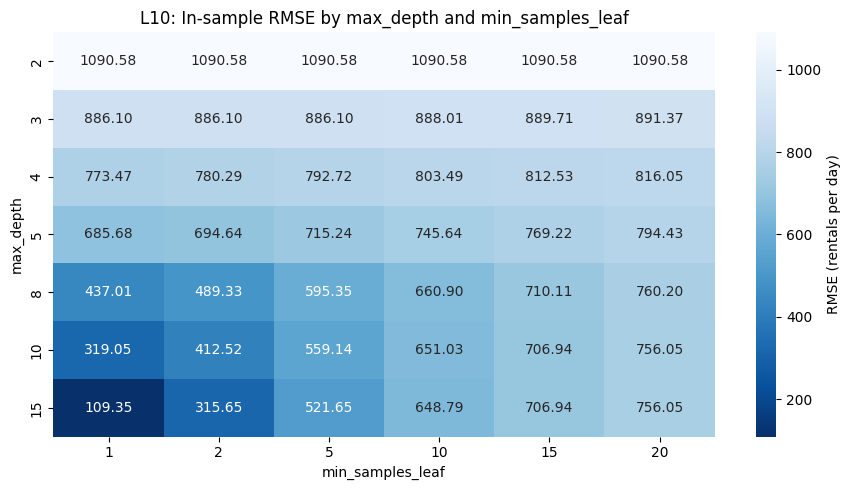

,max_depth,min_samples_leaf,Actual Depth,Number of Leaves,RMSE,R2
0,15,1,15,585,109.346835,0.996810
1,15,2,15,276,315.646018,0.973415
2,10,1,10,279,319.046747,0.972839
3,10,2,10,170,412.523919,0.954591
4,8,1,8,152,437.009323,0.949041
5,8,2,8,116,489.330732,0.936108
6,15,5,15,110,521.651919,0.927389
7,10,5,10,87,559.137578,0.916579
8,8,5,8,70,595.347160,0.905424
9,15,10,13,58,648.788420,0.887683


In [ ]:
import seaborn as sns

pair_results = []

for depth in depth_values:
    for leaf_size in leaf_values:
        model = fit_tree(
            max_depth=depth,
            min_samples_leaf=leaf_size,
        )
        pair_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "Actual Depth": model.get_depth(),
            "Number of Leaves": model.get_n_leaves(),
            **tree_scores(model),
        })

pair_results = pd.DataFrame(pair_results)

rmse_table = pair_results.pivot(
    index="max_depth",
    columns="min_samples_leaf",
    values="RMSE",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    rmse_table,
    annot=True,
    fmt=".2f",
    cmap="Blues_r",
    cbar_kws={"label": "RMSE (rentals per day)"},
    ax=ax,
)
ax.set_title("L10: In-sample RMSE by max_depth and min_samples_leaf")
fig.tight_layout()
fig.savefig("L10_RMSE_depth_and_leaf.png", dpi=200, bbox_inches="tight")
plt.show()

display(
    pair_results.sort_values("RMSE")
    .reset_index(drop=True)
    .style.format({"RMSE": "{:.6f}", "R2": "{:.6f}"})
)

=== คำอธิบายผลลัพธ์การจูนพารามิเตอร์ของ Decision Tree Regression (L10) ===

การวิเคราะห์ประสิทธิภาพของโมเดลผ่านการปรับพารามิเตอร์สำคัญ 2 ตัว มีรายละเอียดดังนี้:

1. **ผลกระทบของความลึกสูงสุด (max_depth Effect) เมื่อกำหนด min_samples_leaf = 1:**
   - **แนวโน้มค่า RMSE และ $R^2$:** เมื่อขยายความลึกของต้นไม้เพิ่มขึ้นจาก `2` ไปเป็น `15` พบว่าค่าความคลาดเคลื่อน **RMSE ลดลงอย่างมีนัยสำคัญ** (จาก `1090.576955` ลดลงเหลือเพียง `109.346835` ครั้งต่อวัน) ขณะเดียวกันค่าความแม่นยำ **$R^2$ เพิ่มขึ้นอย่างมาก** (จาก `0.682639` เพิ่มสูงขึ้นเป็น `0.996810` หรือสามารถอธิบายความผันแปรได้เกือบสมบูรณ์ถึง **99.68%**)
   - **การวิเคราะห์:** ผลลัพธ์นี้เป็นพฤติกรรมปกติของ Decision Tree บนข้อมูลชุดฝึกสอน (In-sample evaluation) เนื่องจากเมื่อปล่อยให้ต้นไม้เติบโตได้อย่างอิสระและมีความลึกมาก (เช่น `max_depth=15`) โมเดลจะจดจำและแบ่งแยกกลุ่มข้อมูลจนละเอียดยิบย่อย ส่งผลให้เกิดความเสี่ยงสูงต่อสภาวะ **Overfitting** ซึ่งอาจทำนายข้อมูลภายนอก (Out-of-sample) ได้ไม่ดีเท่าที่ควร

2. **ผลกระทบของจำนวนตัวอย่างขั้นต่ำในใบ (min_samples_leaf Effect) เมื่อตรึง max_depth = 5:**
   - **แนวโน้มค่า RMSE และ $R^2$:** เมื่อกำหนดจำนวนกลุ่มข้อมูลขั้นต่ำในโหนดใบ (Leaf Nodes) ให้มีขนาดใหญ่ขึ้นจาก `1` ไปถึง `20` พบว่าค่า **RMSE ค่อยๆ เพิ่มขึ้น** (จาก `685.681534` ไปเป็น `794.427327` ครั้งต่อวัน) ส่งผลให้ค่า **$R^2$ ปรับตัวลดลง**ตามลำดับ (จาก `0.874546` ลงมาเหลือ `0.831597`)
   - **การวิเคราะห์:** พารามิเตอร์ `min_samples_leaf` ทำหน้าที่เป็นตัวช่วยลดความซับซ้อนของโครงสร้างต้นไม้ (Regularization) การกำหนดค่าให้สูงขึ้นจะช่วยสกัดกั้นไม่ให้ต้นไม้สร้างเงื่อนไขแยกกลุ่มที่ย่อยเกินไป (เช่น กลุ่มที่มีข้อมูลเพียง 1 หรือ 2 ตัวอย่าง) แม้จะทำให้ผลงานบนข้อมูลชุดเทรนดูดรอปลงเล็กน้อย แต่ช่วยป้องกัน Overfitting และทำให้ต้นไม้มีลักษณะทั่วไป (Generalization) ที่เหมาะสมขึ้นเมื่อนำไปใช้งานจริง

=== คำอธิบายผลลัพธ์การจับคู่พารามิเตอร์ Decision Tree Regression (L10) ===

จากการวิเคราะห์ตารางและกราฟ Heatmap ที่แสดงผลลัพธ์ของการทดลองร่วมกันระหว่าง `max_depth` และ `min_samples_leaf` สามารถสรุปประเด็นสำคัญได้ดังนี้:

1. **จุดที่โมเดลให้ประสิทธิภาพสูงที่สุดบนข้อมูลชุดฝึกสอน (Overfitting Zone):**
   - การจับคู่ที่ให้ค่าความแม่นยำสูงที่สุดคือ **`max_depth = 15` และ `min_samples_leaf = 1`** ซึ่งมีค่า **RMSE ต่ำที่สุดถึง 109.346835 ครั้งต่อวัน** และมี **$R^2$ สูงที่สุดถึง 0.996810 (99.68%)**
   - โครงสร้างที่แท้จริง (Actual Depth) ของต้นไม้โตเต็มพิกัดไปถึงระดับ `15` และมีจำนวนใบ (Number of Leaves) สูงถึง `585` ใบ ซึ่งแสดงถึงสภาวะ **Overfitting ที่รุนแรงมาก** เนื่องจากต้นไม้ปรับเกณฑ์การแบ่งจนตอบสนองข้อมูลรายจุดเกือบสมบูรณ์

2. **ผลของ min_samples_leaf ในการควบคุมความลึกที่แท้จริง (Pruning Effect):**
   - สังเกตได้ว่าเมื่อกำหนด `min_samples_leaf` ให้มีค่าสูงขึ้น แม้เราจะอนุญาตให้มีความลึกสูงสุด (`max_depth`) ถึง `15` แต่โครงสร้างความลึกที่แท้จริง (Actual Depth) ของต้นไม้จะถูกควบคุมไว้ไม่ให้ลึกเกินไปโดยอัตโนมัติ เช่น
     - เมื่อ `max_depth = 15` และ `min_samples_leaf = 10` -> ความลึกจริงจะลดลงเหลือ **13** และมีใบเพียง **58** ใบ
     - เมื่อ `max_depth = 15` และ `min_samples_leaf = 15` -> ความลึกจริงจะลดลงเหลือเพียง **10** และมีใบเพียง **37** ใบ
   - ค่า RMSE และ $R^2$ ของคู่อื่นๆ จะเริ่มสอดคล้องกันและให้ค่าเท่ากันเป๊ะเมื่อพารามิเตอร์ `min_samples_leaf` เป็นตัวจำกัดโครงสร้างหลักแทน เช่น คู่ `(15, 15)` และ `(10, 15)` ต่างก็ให้ผลงานเท่ากันคือ RMSE = `706.944990` และ $R^2 = 0.866644$

3. **พฤติกรรมในระดับความลึกต่ำ (Low Depth / Underfitting Zone):**
   - สำหรับระดับความลึกที่ `2` ไม่ว่าเราจะเลือก `min_samples_leaf` เท่าใดก็ตาม (ตั้งแต่ 1 ถึง 20) ผลงานของโมเดลจะคงที่และเท่ากันทั้งหมด โดยให้ค่า **RMSE = 1090.576955** และ **$R^2 = 0.682639$** ด้วยจำนวนใบที่ฟิกซ์อยู่ที่ `4` ใบเท่ากัน
   - สิ่งนี้ชี้ให้เห็นว่า เมื่อโครงสร้างต้นไม้ตื้นเกินไป พารามิเตอร์ควบคุมอื่นๆ จะไม่มีผล และโมเดลจะตกอยู่ในสภาวะ Underfitting (อธิบายความผันแปรได้ค่อนข้างจำกัด)

4. **แนวคิดการหาจุดสมดุล (Trade-off):**
   - การเลือกโครงสร้างที่ซับซ้อนน้อยกว่า แต่ได้ $R^2$ ที่เหมาะสมบนชุดข้อมูลเทรน (เช่น กลุ่ม `max_depth = 5` ที่มี $R^2$ อยู่ในช่วง 83% - 87% และจำนวนใบน้อยลงเหลือเพียง 19 - 31 ใบ) จะช่วยให้โมเดลมีโอกาสทำนายข้อมูลภายนอกได้เสถียรมากกว่าการพึ่งพาโมเดลที่พุ่งเป้าไปที่ $R^2$ สูงลิ่วแต่มีจำนวนใบถึงเฉียด 600 ใบอย่างแน่นอน
   - ในที่นี้เลือก `max_depth = 5` และ `min_samples_leaf = 10`

# L11.1 - Data Spliting

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# X และ y จาก L9.1 ต้องเป็นข้อมูลก่อน One-Hot Encoding
# preprocessor จาก L9.1 ใช้ passthrough สำหรับตัวแปรเชิงปริมาณ
seeds = [42, 7, 21, 77, 100]
target_bins = pd.qcut(y, q=5, labels=False, duplicates="drop")

ridge_alphas = np.logspace(-4, 4, num=9)
lasso_alphas = np.logspace(-1, 3, num=9)

# แต่ละการทดลองเปลี่ยนพารามิเตอร์ทีละตัว
experiments = [
    {
        "name": "Ridge",
        "estimator": Ridge(),
        "parameter": "alpha",
        "values": ridge_alphas,
        "log_x": True,
        "filename": "L11_1_Ridge_alpha.png",
    },
    {
        "name": "Lasso",
        "estimator": Lasso(max_iter=100_000),
        "parameter": "alpha",
        "values": lasso_alphas,
        "log_x": True,
        "filename": "L11_1_Lasso_alpha.png",
    },
    {
        "name": "Tree depth",
        "estimator": DecisionTreeRegressor(
            min_samples_leaf=1, random_state=42
        ),
        "parameter": "max_depth",
        "values": depth_values,
        "log_x": False,
        "filename": "L11_1_Tree_max_depth.png",
    },
    {
        "name": "Tree leaves",
        "estimator": DecisionTreeRegressor(
            max_depth=5, random_state=42
        ),
        "parameter": "min_samples_leaf",
        "values": leaf_values,
        "log_x": False,
        "filename": "L11_1_Tree_min_samples_leaf.png",
    },
]

records = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=target_bins,
    )

    # Fit เฉพาะ Train แล้วใช้ตัวแปลงชุดเดียวกันกับ Test
    split_preprocessor = clone(preprocessor)
    X_train_encoded = split_preprocessor.fit_transform(X_train)
    X_test_encoded = split_preprocessor.transform(X_test)

    for experiment in experiments:
        parameter = experiment["parameter"]

        for value in experiment["values"]:
            model = clone(experiment["estimator"])
            model.set_params(**{parameter: value})
            model.fit(X_train_encoded, y_train)

            train_pred = model.predict(X_train_encoded)
            test_pred = model.predict(X_test_encoded)

            records.append({
                "Seed": seed,
                "Experiment": experiment["name"],
                "Parameter": parameter,
                "Value": value,
                "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
                "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
            })

results_l11 = pd.DataFrame(records)

print(f"Train: {len(X_train)} แถว | Test: {len(X_test)} แถว")

Train: 584 แถว | Test: 147 แถว


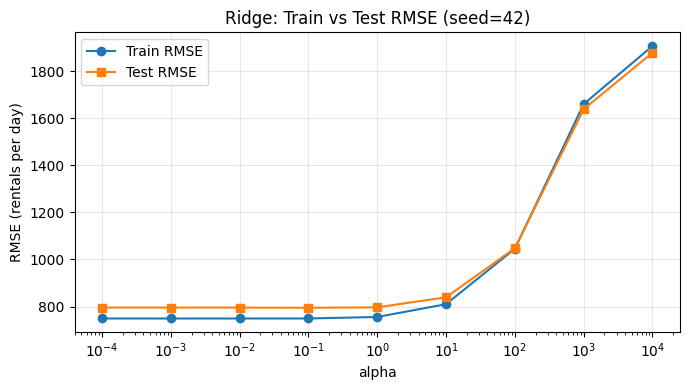

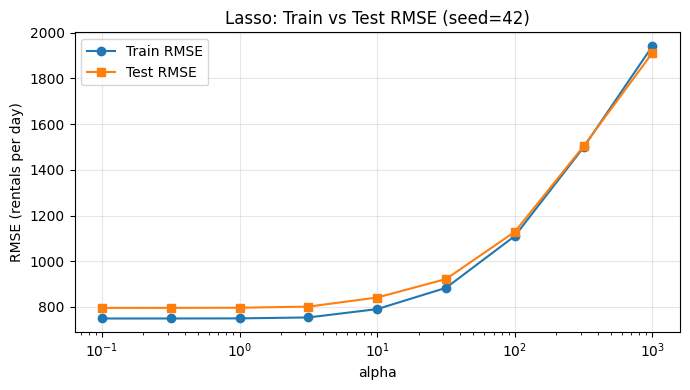

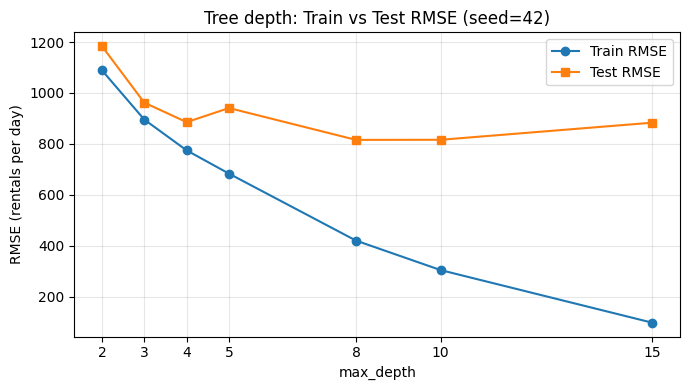

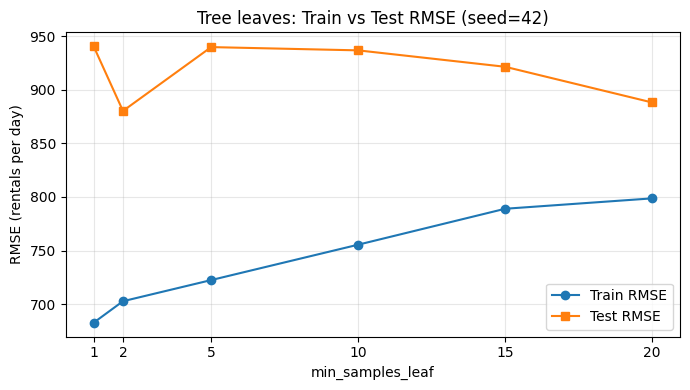

ผลที่ให้ Test RMSE ต่ำสุดในแต่ละ seed


,Experiment,Seed,Parameter,Value,Train RMSE,Test RMSE
0,Lasso,7,alpha,1,755.7774,766.2640
1,Lasso,21,alpha,3.16228,752.7764,803.6256
2,Lasso,42,alpha,0.1,749.3499,795.7199
3,Lasso,77,alpha,0.1,739.7823,827.7336
4,Lasso,100,alpha,10,804.7806,721.8790
5,Ridge,7,alpha,0.0001,755.0276,768.0335
6,Ridge,21,alpha,1,753.5234,813.4191
7,Ridge,42,alpha,0.1,749.4713,794.9469
8,Ridge,77,alpha,0.0001,739.7775,827.7243
9,Ridge,100,alpha,1,767.0464,743.6534


,Seed,42,7,21,77,100,Best value changes?
Experiment,Parameter,,,,,,
Lasso,alpha,0.1,1,3.16228,0.1,10,Yes
Ridge,alpha,0.1,0.0001,1,0.0001,1,Yes
Tree depth,max_depth,8,10,15,8,4,Yes
Tree leaves,min_samples_leaf,2,5,5,20,20,Yes


In [27]:
plot_seed = 42

for experiment in experiments:
    name = experiment["name"]
    parameter = experiment["parameter"]

    plot_data = results_l11.loc[
        (results_l11["Seed"] == plot_seed)
        & (results_l11["Experiment"] == name)
    ].sort_values("Value")

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        plot_data["Value"], plot_data["Train RMSE"],
        marker="o", label="Train RMSE",
    )
    ax.plot(
        plot_data["Value"], plot_data["Test RMSE"],
        marker="s", label="Test RMSE",
    )

    if experiment["log_x"]:
        ax.set_xscale("log")
    else:
        ax.set_xticks(plot_data["Value"])

    ax.set(
        title=f"{name}: Train vs Test RMSE (seed={plot_seed})",
        xlabel=parameter,
        ylabel="RMSE (rentals per day)",
    )
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(experiment["filename"], dpi=200, bbox_inches="tight")
    plt.show()

# เลือกค่าที่ให้ Test RMSE ต่ำสุดของแต่ละการทดลองในแต่ละ seed
# หากคะแนนเท่ากันพอดี ใช้ค่าพารามิเตอร์ที่น้อยกว่า
best_by_seed = (
    results_l11
    .sort_values(["Test RMSE", "Value"])
    .drop_duplicates(subset=["Experiment", "Seed"])
    .sort_values(["Experiment", "Seed"])
)

print("ผลที่ให้ Test RMSE ต่ำสุดในแต่ละ seed")
display(
    best_by_seed[
        ["Experiment", "Seed", "Parameter", "Value", "Train RMSE", "Test RMSE"]
    ].reset_index(drop=True).style.format({
        "Value": "{:g}",
        "Train RMSE": "{:.4f}",
        "Test RMSE": "{:.4f}",
    })
)

# สรุปค่าพารามิเตอร์ที่ดีที่สุดเป็นตารางสำหรับกรอกชีต
seed_summary = best_by_seed.pivot(
    index=["Experiment", "Parameter"],
    columns="Seed",
    values="Value",
).reindex(columns=seeds)

seed_summary["Best value changes?"] = (
    seed_summary[seeds].nunique(axis=1).gt(1).map({True: "Yes", False: "No"})
)

display(seed_summary.style.format({seed: "{:g}" for seed in seeds}))

=== คำอธิบายผลการทดลองในส่วน L11.1 (Data Splitting & Random Seeds Impact) ===

จากการสุ่มแบ่งข้อมูลแบบ Train/Test 80:20 บนชุดข้อมูลที่กระจายตามระดับเป้าหมาย (Stratified by target bins) ผ่านการใช้ค่า Seed ต่างๆ กัน 5 ค่า (`42, 7, 21, 77, 100`) สามารถสรุปผลการวิเคราะห์เปรียบเทียบได้ดังนี้:

1. **ความอ่อนไหวของ Hyperparameter ต่อค่า Seed (Best Value Changes = Yes):**
   - จากตารางสรุปสุดท้าย จะเห็นว่าทุกๆ โมเดลทั้งกลุ่ม Regularized Regression (`Lasso`, `Ridge`) และกลุ่ม Decision Tree (`Tree depth`, `Tree leaves`) ต่างได้รับผลกระทบจากกลุ่มตัวอย่างสุ่มจนทำให้**พารามิเตอร์ที่ดีที่สุดเปลี่ยนไปตามค่า Seed (Yes ทุกโมเดล)**
   - ตัวอย่างเช่น `Ridge` เลือก `alpha = 0.1` ใน Seed 42 แต่เลือก `alpha = 0.0001` ใน Seed 7 และ 77 และเปลี่ยนเป็น `alpha = 1` ใน Seed 21 และ 100
   - แสดงให้เห็นอย่างชัดเจนว่า **การแบ่งข้อมูลแบบ Train/Test เพียงครั้งเดียว (Single Split) ไม่มีความเสถียรเพียงพอ** ในการสรุปผลเพื่อเลือกพารามิเตอร์ที่ดีที่สุดอย่างเด็ดขาด

2. **ความแตกต่างระหว่างประเภทของแบบจำลอง (Linear vs. Tree Models):**
   - **กลุ่มเชิงเส้น (Lasso & Ridge Regression):**
     - สังเกตว่าค่าความคลาดเคลื่อนในการทำนายข้อมูลใหม่ (Test RMSE) จะเกาะกลุ่มกันค่อนข้างสม่ำเสมอ โดยเฉลี่ยอยู่ในระดับประมาณ **720 ถึง 820** ครั้งต่อวัน
     - ช่องว่างระหว่าง Train RMSE และ Test RMSE ค่อนข้างแคบ (Generalize ได้ค่อนข้างดี ไม่ค่อยมีปัญหา Overfitting รุนแรงนัก แม้ค่าพารามิเตอร์ของอัลฟ่าจะต่างกันไปบ้าง)
   - **กลุ่มต้นไม้ (Tree depth & Tree leaves):**
     - มีความผันผวนสูงมากและเกิดช่องว่างที่กว้างมากระหว่าง Train และ Test RMSE (Overfitting)
     - เช่น ที่ Seed 21 (Tree depth) ตัวโมเดลเลือกโครงสร้างลึกสุดที่ `max_depth = 15` มีค่า Train RMSE ต่ำเตี้ยเพียง **66.4039** แต่กลับทำนายชุด Test แย่ที่สุดด้วยค่า RMSE สูงถึง **973.1569** ซึ่งห่างกันอย่างมหาศาล
     - แม้จะปรับด้วยการจำกัดโหนดใบอย่าง `Tree leaves (min_samples_leaf)` ค่า Test RMSE ก็ยังอยู่ในช่วง **824 ถึง 936** ซึ่งสูงกว่ากลุ่มโมเดลเชิงเส้นในเกือบทุกๆ หน้าหน้าการสุ่ม

3. **บทเรียนสำคัญที่ได้รับ:**
   - ผลลัพธ์นี้เน้นย้ำถึง**ความสำคัญของ Cross-Validation** (ซึ่งจะอยู่ในหัวข้อ L12) เนื่องจากหากเราพึ่งพาการสุ่มแบบครั้งเดียว (Hold-out split) ค่าประสิทธิภาพที่เราวัดได้จากชุดทดสอบจะเป็นเพียงภาพสะท้อนชั่วคราวของชุดย่อยนั้นๆ ไม่ใช่ความสามารถที่แท้จริงของแบบจำลองบนประชากรข้อมูลทั้งหมด

#L11.2 - Data Leakage


In [29]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# 1. เรียงข้อมูลตามวันที่ แล้วแบ่ง Train/Test 80/20
dates = pd.to_datetime(bike.loc[X.index, "dteday"], dayfirst=True)
ordered_index = dates.sort_values(kind="stable").index

X_ordered = X.loc[ordered_index]
y_ordered = y.loc[ordered_index]
dates_ordered = dates.loc[ordered_index]

cutoff = int(len(X_ordered) * 0.80)
X_train_l112 = X_ordered.iloc[:cutoff]
X_test_l112 = X_ordered.iloc[cutoff:]
y_train_l112 = y_ordered.iloc[:cutoff]
y_test_l112 = y_ordered.iloc[cutoff:]

train_dates = dates_ordered.iloc[:cutoff]
test_dates = dates_ordered.iloc[cutoff:]

print(f"Train: {len(X_train_l112)} แถว | {train_dates.min():%Y-%m-%d} ถึง {train_dates.max():%Y-%m-%d}")
print(f"Test : {len(X_test_l112)} แถว | {test_dates.min():%Y-%m-%d} ถึง {test_dates.max():%Y-%m-%d}")

# 2. กำหนดคอลัมน์ที่ใช้และการแปลงข้อมูลไว้ใน ColumnTransformer
# remainder="drop" ให้โมเดลรับเฉพาะคอลัมน์ที่ระบุ
leakage_preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", MinMaxScaler(), continuous_columns),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_columns,
        ),
    ],
    remainder="drop",
)

alpha = 0.1

# 3. BEFORE: จงใจ fit preprocessing บน Train + Test
# Ridge ยัง fit ด้วย Train เท่านั้น เพื่อให้เปลี่ยนเพียงวิธี fit preprocessing
before_preprocessor = clone(leakage_preprocessor)
before_preprocessor.fit(X_ordered)

X_train_before = before_preprocessor.transform(X_train_l112)
X_test_before = before_preprocessor.transform(X_test_l112)

before_model = Ridge(alpha=alpha)
before_model.fit(X_train_before, y_train_l112)
pred_before = before_model.predict(X_test_before)

# 4. AFTER: Pipeline fit preprocessing และ Ridge เฉพาะบน Train
after_model = Pipeline(
    steps=[
        ("preprocessor", clone(leakage_preprocessor)),
        ("regression", Ridge(alpha=alpha)),
    ]
)

after_model.fit(X_train_l112, y_train_l112)
pred_after = after_model.predict(X_test_l112)

# 5. เปรียบเทียบคะแนนบน Test ชุดเดียวกัน
comparison_l112 = pd.DataFrame([
    {
        "Scenario": "Before: preprocessing fitted on Train + Test",
        "Test RMSE": np.sqrt(mean_squared_error(y_test_l112, pred_before)),
        "Test R2": r2_score(y_test_l112, pred_before),
    },
    {
        "Scenario": "After: preprocessing fitted on Train only",
        "Test RMSE": np.sqrt(mean_squared_error(y_test_l112, pred_after)),
        "Test R2": r2_score(y_test_l112, pred_after),
    },
])

display(comparison_l112.style.format({
    "Test RMSE": "{:.6f}",
    "Test R2": "{:.6f}",
}))

print("leak type    = contamination")
print("action       = remove")
print("how          = Fit scaling and encoding on Train only using a Pipeline")
print(f"score_before = {comparison_l112.loc[0, 'Test RMSE']:.6f}")
print(f"score_after  = {comparison_l112.loc[1, 'Test RMSE']:.6f}")

Train: 584 แถว | 2011-01-01 ถึง 2012-08-06
Test : 147 แถว | 2012-08-07 ถึง 2012-12-31


,Scenario,Test RMSE,Test R2
0,Before: preprocessing fitted on Train + Test,1105.808936,0.652037
1,After: preprocessing fitted on Train only,1105.808936,0.652037


leak type    = contamination
action       = remove
how          = Fit scaling and encoding on Train only using a Pipeline
score_before = 1105.808936
score_after  = 1105.808936


In [ ]:
used_features = set(continuous_columns + categorical_columns)
target_leak_features = sorted(used_features & {"cnt", "casual", "registered"})

overlapping_dates = pd.Index(train_dates).intersection(pd.Index(test_dates))
temporal_leak = train_dates.max() >= test_dates.min()

audit_l112 = pd.DataFrame([
    {
        "Leak type": "Temporal",
        "Before": "Yes" if temporal_leak else "No",
        "After": "Yes" if temporal_leak else "No",
        "Why": (
            "วันสุดท้ายของ Train อยู่ตรงกับหรือหลังวันแรกของ Test"
            if temporal_leak else
            "ทุกวันใน Train อยู่ก่อนวันแรกของ Test"
        ),
    },
    {
        "Leak type": "Contamination",
        "Before": "Yes",
        "After": "No",
        "Why": (
            "Before fit scaler และ encoder บน Train + Test "
            "ส่วน After ให้ Pipeline fit เฉพาะ Train"
        ),
    },
    {
        "Leak type": "Target",
        "Before": "Yes" if target_leak_features else "No",
        "After": "Yes" if target_leak_features else "No",
        "Why": (
            f"ตัวแปรที่เกี่ยวข้องโดยตรงกับเป้าหมาย: {', '.join(target_leak_features)}"
            if target_leak_features else
            "ไม่ใช้ cnt, casual หรือ registered เป็นตัวแปรทำนาย"
        ),
    },
    {
        "Leak type": "Group",
        "Before": "Yes" if len(overlapping_dates) else "No",
        "After": "Yes" if len(overlapping_dates) else "No",
        "Why": f"ใช้วันที่เป็นหน่วยกลุ่ม พบวันที่ซ้ำข้าม Train/Test {len(overlapping_dates)} วัน",
    },
])

display(audit_l112)

,Leak type,Before,After,Why
0,Temporal,No,No,ทุกวันใน Train อยู่ก่อนวันแรกของ Test
1,Contamination,Yes,No,Before fit scaler และ encoder บน Train + Test ...
2,Target,No,No,"ไม่ใช้ cnt, casual หรือ registered เป็นตัวแปรท..."
3,Group,No,No,ใช้วันที่เป็นหน่วยกลุ่ม พบวันที่ซ้ำข้าม Train/...


**=== คำอธิบายผลการวิเคราะห์และตรวจสอบ Data Leakage (L11.2) ===**

จากการทดสอบเปรียบเทียบและทำแผนผังตรวจสอบการรั่วไหลของข้อมูล (Data Leakage Audit) ในการแบ่งข้อมูลแบบตามลำดับเวลา (Chronological Split) สามารถวิเคราะห์ประเด็นสำคัญได้ดังนี้:

**1. ผลลัพธ์จากการวัดประสิทธิภาพ (Test Score Comparison)**
* **เปรียบเทียบผลลัพธ์ก่อนและหลัง:**
  * **Before** (ประมวลผลเตรียมข้อมูลร่วมกันก่อนแบ่ง): มีค่า **Test RMSE = 1,105.808936** และ **Test $R^2$ = 0.652037**
  * **After** (ใช้ Pipeline เพื่อเรียนรู้โครงสร้างเฉพาะชุด Train เท่านั้น): มีค่า **Test RMSE = 1,105.808936** และ **Test $R^2$ = 0.652037**
* **ข้อสังเกต:** ค่าคะแนนการทำนายชุดทดสอบ (Test Score) ของทั้งสองวิธีได้ผลลัพธ์**เท่ากันพอดี**

**2. การวิเคราะห์สาเหตุเชิงลึกและประเภทการรั่วไหล (Leakage Audit)**

* **Contamination Leakage (การปนเปื้อนข้อมูล):**
  * **พบปัญหาในขั้นตอนแรก (Before):** มีสถานะเป็น **Yes** เนื่องจากโมเดลแอบเห็นช่วงของค่าขั้นต่ำและสูงสุด (Min/Max) ของชุดทดสอบ (Test Set) ตั้งแต่ขั้นตอนการสเกลข้อมูล ทำให้ระดับสารสนเทศบางส่วนจากอนาคตรั่วไหลไปสู่อดีต
  * **การแก้ไข (After):** ปรับปรุงสถานะเป็น **No** โดยการนำระบบ `Pipeline` มาควบคุม เพื่อสั่งให้โมเดลประมวลผล `.fit_transform()` เฉพาะบนชุด Train เท่านั้น และส่งต่อไปยังชุด Test เพียงแค่ `.transform()` ซึ่งสะท้อนการทำงานจริงเมื่อระบบต้องไปประมวลผลข้อมูลใหม่ที่คลาดสายตามาก่อน
  * **ทำไมคะแนน RMSE ไม่เปลี่ยน?** เนื่องจากตัวแปรที่ใช้ (เช่น `temp`, `hum`, `windspeed`) ในชุดทดสอบ (ช่วงเดือนสิงหาคม - ธันวาคม 2012) มีขอบเขตค่า (Range) ที่ใกล้เคียงและยังอยู่ภายใต้กรอบของชุดฝึกสอน (มกราคม 2011 - สิงหาคม 2012) การปนเปื้อนในครั้งนี้จึงไม่ส่งผลกระทบให้เกิดความต่างของระดับตัวเลขอย่างเป็นนัยสำคัญ แต่การแก้ไขผ่านระบบ Pipeline ถือเป็น **Best Practice** ที่ป้องกันข้อผิดพลาดกรณีข้อมูลใหม่มีความเหวี่ยงแบบสุดโต่งได้ขาดลอย

* **Temporal Leakage (การรั่วไหลเชิงมิติเวลา):**
  * **ผลประเมิน:** **No**
  * **เหตุผล:** เนื่องจากทีมงานได้ออกแบบวิธีสอดคล้องกับแนวคิดเชิงเวลาแบบ **Chronological Split 80:20** ทำให้ข้อมูลชุดฝึกสอน (Train Set) ทั้งหมด สิ้นสุดลงที่วันที่ `2012-08-06` และข้อมูลชุดทดสอบ (Test Set) เริ่มต้นขึ้นในวันที่ `2012-08-07` เป็นต้นไป ข้อมูลอดีตและอนาคตจึงแยกกันเด็ดขาดโดยไม่มีข้อมูลวันเวลาปะปนกัน

* **Target Leakage (การรั่วไหลจากตัวแปรเป้าหมาย):**
  * **ผลประเมิน:** **No**
  * **เหตุผล:** ในการคัดเลือกตัวแปรเข้ามาทำนายนั้น ไม่มีการนำข้อมูลผลลัพธ์ปลายทางที่คำนวณมาโดยตรง เช่น `casual` (จำนวนเช่าทั่วไป), `registered` (จำนวนเช่าของสมาชิก) หรือ `cnt` (ตัวแปรเป้าหมายเอง) มาเป็นฟีเจอร์สอนโมเดล ทำให้ไม่มีการเฉลยคำตอบอ้อมๆ ล่วงหน้าแก่ตัวแบบ

* **Group Leakage (การรั่วไหลระดับกลุ่มข้อมูลที่มีความซ้ำซ้อน):**
  * **ผลประเมิน:** **No**
  * **เหตุผล:** ข้อมูลชุดนี้ใช้ วันที่บันทึกข้อมูล (`dteday`) เป็นระเบียนกลุ่มหลักในการจัดแบ่ง ซึ่งไม่พบการบันทึกซ้ำซ้อนของวันที่เดียวกันระหว่างชุดข้อมูลทั้งสองฝั่ง (Overlapping dates = 0 วัน) ทำให้ตัดปัญหาตัวแบบจดจำกลุ่มข้อมูลข้ามฝั่งได้สนิท

# L12 - Performance Metrics & Cross-Validation

In [31]:
from time import perf_counter

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

# ใช้ข้อมูลก่อน preprocessing จาก L11.2 ที่เรียงตามวันที่แล้ว
X_train_l12 = X_train_l112.copy()
X_test_l12 = X_test_l112.copy()
y_train_l12 = y_train_l112.copy()
y_test_l12 = y_test_l112.copy()

random_state = 42
alpha_grid = np.logspace(-4, 4, num=9)
main_scoring = "neg_root_mean_squared_error"

# Fit scaler และ encoder ใหม่ภายในชุดฝึกของแต่ละการแบ่ง
ridge_pipeline = Pipeline([
    ("preprocessor", clone(leakage_preprocessor)),
    ("regression", Ridge(random_state=random_state)),
])


def regression_scores(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


# Baseline 1: ทำนายด้วยค่าเฉลี่ย cnt จาก Train
train_mean = y_train_l12.mean()
pred_mean = np.full(len(X_test_l12), train_mean)

# Baseline 2: ทำนายด้วยค่าเฉลี่ย cnt ของวันในสัปดาห์เดียวกันจาก Train
weekday_mean = y_train_l12.groupby(
    X_train_l12["weekday"], observed=True
).mean()

pred_weekday = (
    X_test_l12["weekday"].astype(object)
    .map(weekday_mean)
    .fillna(train_mean)
    .to_numpy(dtype=float)
)

baseline_results = pd.DataFrame([
    {
        "Baseline": "Train mean",
        **regression_scores(y_test_l12, pred_mean),
    },
    {
        "Baseline": "Train mean by weekday",
        **regression_scores(y_test_l12, pred_weekday),
    },
])

display(baseline_results.style.format({"RMSE": "{:.4f}", "MAE": "{:.4f}"}))

,Baseline,RMSE,MAE
0,Train mean,2560.5558,2290.4127
1,Train mean by weekday,2550.8074,2287.1747


In [ ]:
# 2-way: เลือก alpha ด้วย TimeSeriesSplit ภายใน Train 80%
search_2way = GridSearchCV(
    estimator=clone(ridge_pipeline),
    param_grid={"regression__alpha": alpha_grid},
    scoring=main_scoring,
    cv=TimeSeriesSplit(n_splits=5),
    refit=True,
)
search_2way.fit(X_train_l12, y_train_l12)

best_alpha_2way = search_2way.best_params_["regression__alpha"]
pred_2way = search_2way.predict(X_test_l12)

# 3-way: กัน 20% ช่วงท้ายของ Train 80% เป็น Validation
cutoff = int(len(X_train_l12) * 0.80)

X_subtrain = X_train_l12.iloc[:cutoff]
y_subtrain = y_train_l12.iloc[:cutoff]
X_val = X_train_l12.iloc[cutoff:]
y_val = y_train_l12.iloc[cutoff:]

validation_records = []

for alpha in alpha_grid:
    model = clone(ridge_pipeline).set_params(regression__alpha=alpha)
    model.fit(X_subtrain, y_subtrain)
    val_pred = model.predict(X_val)

    validation_records.append({
        "alpha": alpha,
        "Validation RMSE": regression_scores(y_val, val_pred)["RMSE"],
    })

validation_results = pd.DataFrame(validation_records)
best_row = validation_results.loc[validation_results["Validation RMSE"].idxmin()]
best_alpha_3way = best_row["alpha"]

# รวม Subtrain + Validation เพื่อ fit โมเดลสุดท้าย
model_3way = clone(ridge_pipeline).set_params(regression__alpha=best_alpha_3way)
model_3way.fit(X_train_l12, y_train_l12)
pred_3way = model_3way.predict(X_test_l12)

split_records = []

for method, alpha, predictions in [
    ("2-way (CV within Train)", best_alpha_2way, pred_2way),
    ("3-way (single Validation)", best_alpha_3way, pred_3way),
]:
    scores = regression_scores(y_test_l12, predictions)
    split_records.append({
        "Method": method,
        "Best alpha": alpha,
        "Test RMSE": scores["RMSE"],
        "Test MAE": scores["MAE"],
        "Underprediction rate": np.mean(predictions < y_test_l12.to_numpy()),
    })

split_results = pd.DataFrame(split_records)

print(
    f"3-way split: Subtrain = {len(X_subtrain)}, "
    f"Validation = {len(X_val)}, Test = {len(X_test_l12)}"
)

display(split_results.style.format({
    "Best alpha": "{:g}",
    "Test RMSE": "{:.4f}",
    "Test MAE": "{:.4f}",
    "Underprediction rate": "{:.1%}",
}))

3-way split: Subtrain = 467, Validation = 117, Test = 147


,Method,Best alpha,Test RMSE,Test MAE,Underprediction rate
0,2-way (CV within Train),0.0001,1103.6690,804.4628,60.5%
1,3-way (single Validation),1,1122.7753,821.1171,61.2%


In [ ]:
cv_alpha = 0.1
fold_records = []
summary_records = []

for k in [5, 10]:
    splitter = TimeSeriesSplit(n_splits=k)
    scores_this_k = []
    start_time = perf_counter()

    for fold, (train_idx, val_idx) in enumerate(
        splitter.split(X_train_l12), start=1
    ):
        X_fold_train = X_train_l12.iloc[train_idx]
        y_fold_train = y_train_l12.iloc[train_idx]
        X_fold_val = X_train_l12.iloc[val_idx]
        y_fold_val = y_train_l12.iloc[val_idx]

        fold_model = clone(ridge_pipeline).set_params(
            regression__alpha=cv_alpha
        )
        fold_model.fit(X_fold_train, y_fold_train)
        predictions = fold_model.predict(X_fold_val)
        scores = regression_scores(y_fold_val, predictions)

        scores_this_k.append(scores)
        fold_records.append({
            "K": k,
            "Fold": fold,
            "Train rows": len(train_idx),
            "Validation rows": len(val_idx),
            **scores,
        })

    runtime = perf_counter() - start_time
    fold_scores = pd.DataFrame(scores_this_k)

    summary_records.append({
        "K": k,
        "RMSE (Mean ± SD)": (
            f"{fold_scores['RMSE'].mean():.4f} ± "
            f"{fold_scores['RMSE'].std(ddof=1):.4f}"
        ),
        "MAE (Mean ± SD)": (
            f"{fold_scores['MAE'].mean():.4f} ± "
            f"{fold_scores['MAE'].std(ddof=1):.4f}"
        ),
        "Runtime (seconds)": runtime,
    })

cv_fold_results = pd.DataFrame(fold_records)
cv_summary = pd.DataFrame(summary_records)

print("คะแนน Validation ราย fold")
display(cv_fold_results.style.format({"RMSE": "{:.4f}", "MAE": "{:.4f}"}))

print("สรุป Cross-Validation")
display(cv_summary.style.format({"Runtime (seconds)": "{:.6f}"}))

คะแนน Validation ราย fold


,K,Fold,Train rows,Validation rows,RMSE,MAE
0,5,1,99,97,1497.7428,1379.1213
1,5,2,196,97,957.3923,795.6137
2,5,3,293,97,1044.6836,751.5597
3,5,4,390,97,1151.8605,918.1132
4,5,5,487,97,1002.6624,797.7045
5,10,1,54,53,793.2830,633.8308
6,10,2,107,53,1426.8088,1311.1077
7,10,3,160,53,781.6346,580.3269
8,10,4,213,53,842.3287,706.9938
9,10,5,266,53,2260.8543,2202.3136


สรุป Cross-Validation


,K,RMSE (Mean ± SD),MAE (Mean ± SD),Runtime (seconds)
0,5,1130.8683 ± 217.3684,928.4225 ± 259.4424,0.325581
1,10,1096.8016 ± 473.2706,931.3623 ± 507.4663,0.358310


**=== คำอธิบายผลลัพธ์การวัดประสิทธิภาพและการตรวจสอบไขว้ (L12: Performance Metrics & Cross-Validation) ===**

จากการวิเคราะห์และประเมินผลการทำนายจำนวนครั้งการเช่าจักรยานรายวันด้วยตัวแบบ **Ridge Regression** ผ่านกลยุทธ์การแบ่งข้อมูลที่คำนึงถึงมิติเวลาและการทดสอบ Cross-Validation แบบต่าง ๆ สามารถวิเคราะห์ประเด็นสำคัญได้ดังนี้:

---

**1. การเปรียบเทียบกับตัวแบบเกณฑ์มาตรฐาน (Baseline Comparison)**
* **Train mean (ทำนายด้วยค่าเฉลี่ยรวม):** ให้ค่า **Test RMSE = 2,560.5558** และ **MAE = 2,290.4127** ครั้งต่อวัน
* **Train mean by weekday (ทำนายด้วยค่าเฉลี่ยจำแนกรายวันในสัปดาห์):** ให้ค่า **Test RMSE = 2,550.8074** และ **MAE = 2,287.1747** ครั้งต่อวัน
* **ข้อสังเกต:** ตัวแบบเกณฑ์มาตรฐานทั้งสองแบบให้ความคลาดเคลื่อนที่สูงมาก (RMSE สูงกว่า 2,500 ครั้งต่อวัน) เนื่องจากไม่ได้ใช้ตัวแปรสภาพแวดล้อมหรืออุณหภูมิเข้ามาช่วยคำนวณเลย

---

**2. การเปรียบเทียบระหว่างวิธี 2-way (CV within Train) และ 3-way Split**

* **วิธี 2-way Split (GridSearchCV ด้วย TimeSeriesSplit (5-Fold) บน Train 80%):**
  * **ค่าพารามิเตอร์ที่ดีที่สุด (Best alpha):** `0.0001` (แทบไม่มีการลงโทษน้ำหนัก)
  * **ประสิทธิภาพบน Test Set:** **RMSE = 1,103.6690** และ **MAE = 804.4628**
  * **อัตราทำนายต่ำกว่าจริง (Underprediction Rate):** `60.5%`

* **วิธี 3-way Split (แบ่ง Subtrain 80% / Validation 20% แบบเดี่ยวเชิงเวลา):**
  * **ค่าพารามิเตอร์ที่ดีที่สุด (Best alpha):** `1` (มีการคุมน้ำหนักฟีเจอร์เพิ่มขึ้น)
  * **ประสิทธิภาพบน Test Set:** **RMSE = 1,122.7753** และ **MAE = 821.1171**
  * **อัตราทำนายต่ำกว่าจริง (Underprediction Rate):** `61.2%`

* **การวิเคราะห์และสรุปผลเปรียบเทียบ:**
  1. ทั้งสองวิธีสามารถทำคะแนน RMSE ปรับตัวลดลงจาก Baseline ได้อย่างมาก (ลดลงเกิน 55%)
  2. **วิธี 2-way Split (ผ่าน CV) ให้ผลลัพธ์บนชุดข้อมูลทดสอบจริงที่ดีกว่าวิธี 3-way** ทั้งในแง่ RMSE (ต่ำกว่า 19 หน่วย) และ MAE (ต่ำกว่า 16 หน่วย)
  3. เนื่องจากวิธี 3-way Split ที่ใช้การแบ่ง Validation เพียงรอบเดียวเชิงเวลานั้น ตัวแบบถูกลดทอนปริมาณข้อมูลสอนย่อยเหลือเพียง 467 แถว (Subtrain) ส่งผลให้การประเมินสัญญาณมีความคลาดเคลื่อนและอ่อนไหวต่อช่วงเวลาของ Validation ในขณะที่วิธี 2-way มีการหมุนเวียนข้อมูลทดสอบเสมือนผ่าน TimeSeriesSplit หลายรอบ ทำให้สามารถเลือกค่า `alpha` ที่มีความเสถียรและเหมาะสมกับโครงสร้างข้อมูลระยะยาวได้แม่นยำกว่า
  4. ทั้งสองวิธีมีพฤติกรรมทำนายต่ำกว่าความเป็นจริงเล็กน้อย (Underprediction rate อยู่ที่ประมาณ 60%)

---

**3. การวิเคราะห์ประสิทธิภาพความเสถียรราย Fold (5-Fold vs 10-Fold TimeSeriesSplit)**

จากการรันประเมินเพื่อวัดความแปรปรวน (Variance) ของประสิทธิภาพผ่านกระบวนการตรวจสอบไขว้ เปรียบเทียบระหว่างการแบ่ง 5 และ 10 ส่วน (ตรึงค่า `alpha = 0.1`) มีผลสรุปดังนี้:

| เกณฑ์เปรียบเทียบ | 5-Fold Cross-Validation | 10-Fold Cross-Validation |
| :--- | :---: | :---: |
| **RMSE (Mean ± SD)** | **1,130.8683 ± 217.3684** | **1,096.8016 ± 473.2706** |
| **MAE (Mean ± SD)** | **928.4225 ± 259.4424** | **931.3623 ± 507.4663** |
| **เวลาทำงาน (Runtime)** | **0.3256 วินาที** | **0.3583 วินาที** |

* **การวิเคราะห์เชิงลึก:**
  * **ด้านความแม่นยำเฉลี่ย (Mean Accuracy):** วิธี **10-Fold** ให้ค่าเฉลี่ย RMSE ที่ต่ำกว่า 5-Fold เล็กน้อย (1,096 เทียบกับ 1,130) เนื่องจากจำนวนโฟลด์ที่มากขึ้นทำให้ในรอบท้าย ๆ ตัวแบบย่อยได้รับจำนวนข้อมูลสอนต่อรอบที่ใหญ่ขึ้นเรื่อย ๆ จนเกือบเต็มจำนวน
  * **ด้านความเสถียร (Model Stability/Variance):** แม้ 10-Fold จะได้ค่าเฉลี่ยที่ดีกว่า แต่พบว่า**ค่าความเบี่ยงเบนมาตรฐาน (SD) กว้างกว่า 5-Fold ถึงเท่าตัว** (SD ของ 10-Fold = ±473.2706 ในขณะที่ 5-Fold มีค่าเพียง ±217.3684)
  * สังเกตผลราย Fold ของ 10-Fold พบความเหวี่ยงของคะแนนอย่างรุนแรง เช่น ใน Fold 3 ได้ RMSE ต่ำเพียง `781.6346` แต่พอใน Fold 5 กลับพุ่งไปสูงถึง `2,260.8543` แสดงให้เห็นว่าการแบ่งข้อมูลออกเป็นชิ้นย่อยขนาดเล็กเกินไป (ใน 10-Fold มีข้อมูล Validation เพียงโฟลด์ละ ~53 แถว) จะมีความอ่อนไหวต่อสิ่งรบกวน (Noise) หรือข้อมูลที่มีพฤติกรรมสุดโต่งในช่วงเวลานั้น ๆ สูงมาก
  * **ด้านเวลาประมวลผล (Runtime):** 5-Fold ทำงานได้เร็วกว่า 10-Fold เล็กน้อย เนื่องจากรอบการวนลูปเพื่อเทรนโมเดลมีจำนวนน้อยกว่า

**บทสรุปและข้อเสนอแนะ:**
สำหรับการประเมินผลตัวแบบเพื่อรายงานความเสถียรในสถานการณ์จริง **การเลือกใช้ 5-Fold TimeSeriesSplit เป็นตัวเลือกที่ปลอดภัยและสะท้อนความสามารถที่คงเส้นคงวามากกว่า** เนื่องจากให้ค่าความแปรปรวน (Variance) ระหว่างพับที่ต่ำ ควบคุมความผันผวนของความคลาดเคลื่อนได้ดี และใช้เวลาคำนวณน้อยกว่า

#บทสรุปข้อคิดที่สำคัญ (Takeaways)

1. **ผลลัพธ์ที่น่าประหลาดใจที่สุด:** โมเดล Decision Tree (max_depth=15) เกิด Overfitting รุนแรงมาก โดย $R^2$ บนชุด Train สูงถึง 99.68% แต่เมื่อทดสอบใน L11.1 (Seed 21) ประสิทธิภาพในชุด Test กลับลดลงอย่างมาก โดยมีช่องว่างคลาดเคลื่อนสูงกว่าโมเดลเชิงเส้นพื้นฐานเกือบเท่าตัว
2. **สิ่งที่จะปรับเปลี่ยนหลังจากนี้:** หลีกเลี่ยงการสุ่มแยกข้อมูลแบบทั่วไป (Random Split) กับข้อมูลที่มีมิติเวลา แล้วเปลี่ยนมาใช้ **Chronological Split** อย่างเคร่งครัด พร้อมทั้งใช้ระบบ **Pipeline** เสมอเพื่อควบคุมและป้องกันการรั่วไหลของข้อมูล (Data Leakage) ในขั้นตอน Preprocessing
3. **ระดับความน่าเชื่อถือของผลลัพธ์ (Test Score Reliability):** อยู่ในระดับ **ปานกลาง** แม้กระบวนการทดสอบเชิงเวลาจะปราศจากปัญหา Data Leakage และสะท้อนการทำงานจริง แต่การทดสอบด้วยข้อมูลช่วงปลายปี 2012 เพียงช่วงสั้น ๆ อาจมีความผันผวนจากปัจจัยฤดูกาลที่เปลี่ยนแปลงไป (Temporal Shift)
4. **แนวทางการพัฒนาต่อในอนาคต:** มุ่งเน้นทำ **Feature Engineering** สร้างตัวแปรเชิงอนุพันธ์ เช่น Lag Features หรือดัชนีพยากรณ์อากาศล่วงหน้า และเปลี่ยนไปประยุกต์ใช้โมเดลกลุ่ม Ensemble (เช่น Random Forest, XGBoost) เพื่อดึงประสิทธิภาพสูงสุดโดยไม่เกิดปัญหา Overfitting

#บทบาทและความรับผิดชอบของสมาชิกในกลุ่ม (Member Contributions)

สมาชิกในกลุ่มได้แบ่งงานตามส่วนงานหลัก โดยแต่ละคนจะรับผิดชอบกระบวนการทั้งหมดตั้งแต่การพัฒนาโค้ด การประเมินผล ไปจนถึงการเขียนวิเคราะห์ผลลัพธ์ในหัวข้อนั้น ๆ ดังนี้

**ตารางสรุปการแบ่งงานแยกตามหัวข้อความรับผิดชอบ**

| หัวข้อการทดลอง (Topic) | สมาชิกผู้รับผิดชอบหลักโดยสิ้นเชิง | ขอบเขตหน้าที่และความรับผิดชอบหลัก |
| :--- | :--- | :--- |
| **L0: Data Preparation & Cleaning** | **นายก้องภพ สายสุด** | นำเข้าข้อมูลดิบ, ทำความสะอาดข้อมูล (Data Cleaning), แปลงชนิดข้อมูล และเขียนกราฟแสดงการกระจายตัวเพื่อทำ EDA ภาพรวม |
| **L9.1: Linear Regression Model** | **นายพศวีร์ คอนจอหอ** | พัฒนาโค้ด Train โมเดล Linear Regression บนข้อมูลทั้งหมด และประเมินค่า RMSE กับ R-square |
| **L9.2: Regularized Regression (Ridge)** | **นายวราฤทธิ์ พานิชกิจโกศลกุล** | พัฒนาและทดสอบ Ridge Regression เปรียบเทียบประสิทธิภาพภายใต้ค่า Alpha ที่แตกต่างกัน 9 ระดับ |
| **L10: Decision Tree Regression Model** | **นายก้องภพ สายสุด** | สร้างโมเดลจำลองต้นไม้ตัดสินใจ ปรับแต่งระดับความลึก (max_depth) และขนาดใบ (min_samples_leaf) ร่วมกับการวาดภาพโครงสร้างต้นไม้ และวิเคราะห์ปัญหา Overfitting |
| **L11.1: Data Splitting (Train/Test)** | **นายพศวีร์ คอนจอหอ** | ดำเนินการแบ่งข้อมูลออกเป็นชุด Train และ Test ในสัดส่วน 80:20 แบบสุ่มอิงกลุ่มเป้าหมาย (Stratified Split by target bins) ภายใต้ Seed 5 ค่า และวิเคราะห์ผลกระทบของค่าสุ่มต่อพารามิเตอร์ |
| **L11.2: Data Leakage Analysis** | **นายวราฤทธิ์ พานิชกิจโกศลกุล** | ดำเนินการจัดแบ่งข้อมูลตามลำดับเวลา (Chronological Split) และเปรียบเทียบผลลัพธ์เพื่อวิเคราะห์การรั่วไหลของข้อมูลประเภท Contamination ในขั้นตอน Preprocessing |
| **L12: Cross-Validation** | **นายวราฤทธิ์ พานิชกิจโกศลกุล** | เขียนโค้ดระบบประเมินผลเปรียบเทียบวิธี 2-way Split (CV) และ 3-way Split รวมถึงทดสอบ 5-Fold และ 10-Fold TimeSeriesSplit เพื่อวัดความเสถียรและเวลารัน |
| **Takeaways & Documentation** | **สมาชิกทุกคนร่วมกันดำเนินการ** | สรุปประเด็นบทเรียนสำคัญร่วมกัน เรียบเรียงเนื้อหา และเกลาภาษาเพื่อความถูกต้องสมบูรณ์ของรายงานสัมมนาในขั้นตอนสุดท้าย |

### **รายละเอียดผลงานแยกรายบุคคลตามส่วนที่ได้รับมอบหมาย**

1. **นายก้องภพ สายสุด (รหัสนิสิต 69199160398)**
   * **ความรับผิดชอบหลัก:** การนำเข้า จัดเตรียม ทำความเข้าใจลักษณะทางสถิติและการกระจายตัวของข้อมูลดิบทั้งหมด ตลอดจนการพัฒนาและปรับแต่งตัวแบบประเภทต้นไม้ตัดสินใจ (Decision Tree)
   * **ผลงานสำคัญ:** รับผิดชอบจัดทำส่วน **L0** (Data Preparation, Cleaning, EDA) และส่วน **L10** (Decision Tree Regressor) พร้อมทุ่มเทวิเคราะห์โครงสร้างความลึกและพฤติกรรมการเกิด Overfitting ของโมเดล

2. **นายพศวีร์ คอนจอหอ (รหัสนิสิต 69199160411)**
   * **ความรับผิดชอบหลัก:** การทดสอบตัวแบบถดถอยเชิงเส้นธรรมดา และการออกแบบระบบทดลองแยกส่วนข้อมูลเพื่อวัดผลกระทบของความผันผวนจากการสุ่ม
   * **ผลงานสำคัญ:** รับผิดชอบจัดทำส่วน **L9.1** (Linear Regression Model) และส่วน **L11.1** (Data Splitting) โดยทดลองสุ่มแยกข้อมูลแบบ Train/Test 80:20 อิงกลุ่มเป้าหมาย (Stratified Split) ข้ามค่า Random Seeds ทั้งหมด 5 ค่า เพื่อวิเคราะห์เสถียรภาพและช่องว่าง (Gap) ของคะแนน RMSE ระหว่าง Train และ Test

3. **นายวราฤทธิ์ พานิชกิจโกศลกุล (รหัสนิสิต 69199160420)**
   * **ความรับผิดชอบหลัก:** การควบคุมความซับซ้อนของแบบจำลองด้วยวิธีรักษาสมดุลค่าน้ำหนัก (Regularization), การตรวจวิเคราะห์ประเมินการรั่วไหลของข้อมูล และการพัฒนาโครงสร้างระบบการตรวจสอบไขว้เชิงเวลาเพื่อวัดผลจริง
   * **ผลงานสำคัญ:** รับผิดชอบจัดทำส่วน **L9.2** (Ridge Regression), ส่วน **L11.2** (Data Leakage) เปรียบเทียบวิธีคุมการทดลองแบบดั้งเดิมกับ Pipeline เพื่อสกัดปัญหา Contamination และส่วน **L12** (Cross-Validation) เปรียบเทียบระบบ 2-way Split กับ 3-way Split รวมถึงทดสอบความแปรปรวนเชิงเวลารายพับผ่าน 5-Fold และ 10-Fold TimeSeriesSplit